# EfficientNet-B0: African Fine-Tuning

The model selection notebook chose EfficientNet-B0 using a rule fixed before the results were seen (section 6 of that notebook). This notebook repeats the African fine-tuning for EfficientNet-B0, with the same folds and settings that were used for ResNet18 in the model training notebook (section 8), so the two can be compared directly.

## 0. Setup

In [22]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
MODELS = ROOT / "models"

from src.training import fine_tune, get_device, load_model, make_loader, predict

ARCH = "efficientnet_b0"
SPANISH_WEIGHTS = MODELS / "selection" / f"{ARCH}.pt"

random_seed = 42
np.random.seed(random_seed)
torch.manual_seed(random_seed)

PLANES = ["Fetal abdomen", "Fetal brain", "Fetal femur", "Fetal thorax"]
SHORT_NAMES = [plane.replace("Fetal ", "") for plane in PLANES]
device = get_device()
print("Device:", device)

Device: mps


## 1. Loading the data and the Spanish model

The starting point is the EfficientNet-B0 trained on the Spanish images in the model selection notebook. Its predictions on the African development images, before any African training, are recalculated here as the comparison point.

In [23]:
african_clean = pd.read_csv(PROCESSED / "african_clean.csv")
african_images = np.load(PROCESSED / "african_processed.npz")["images"]

development = african_clean[african_clean["partition"] == "development"]
dev_images = african_images[development.index]
dev_labels = development["label"].to_numpy()

spanish_model = load_model(SPANISH_WEIGHTS, device, arch=ARCH)
_, pred_af, _ = predict(spanish_model, make_loader(dev_images, dev_labels), device)
print(f"Spanish model on African development: accuracy {(pred_af == dev_labels).mean():.3f} | "
      f"macro-F1 {f1_score(dev_labels, pred_af, average='macro'):.3f}")

Spanish model on African development: accuracy 0.941 | macro-F1 0.934


## 2. Fine-tuning settings

The settings are the same as for ResNet18, so that only the network differs.

| Setting | Value |
|---|---|
| Starting weights | EfficientNet-B0 trained on the Spanish images |
| Optimiser | Adam, learning rate 0.00005, weight decay 0.0001 |
| Batch size | 16 |
| Epochs | 5, fixed (no early stopping, because the held-out fold is only for scoring) |
| Class weights | Recalculated from each fold's training images |
| Augmentation | Training images only |
| Folds | 5-fold cross-validation grouped by patient, same seed and therefore the same folds as for ResNet18 |

The African test images are not used.

### 2.1 Patient-grouped folds

In [12]:
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_seed)
fold_of_image = np.zeros(len(development), dtype=int)
for fold, (_, held_out) in enumerate(folds.split(dev_images, dev_labels, development["patient_id"]), start=1):
    fold_of_image[held_out] = fold

development = development.assign(fold=fold_of_image)
pd.crosstab(development["fold"], development["Plane"], margins=True)

Plane,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,All
fold,,,,,
1,17,18,17,10,62
2,19,19,19,11,68
3,18,18,18,13,67
4,17,16,16,9,58
5,19,19,19,9,66
All,90,90,89,52,321


## 3. Fine-tuning each fold

In [13]:
def new_african_model(train_images, train_labels, seed):
    """Starts from the Spanish EfficientNet-B0 and fine-tunes it on the given African images."""
    torch.manual_seed(seed)
    model = load_model(SPANISH_WEIGHTS, device, arch=ARCH)
    class_weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=train_labels)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-5, weight_decay=1e-4)
    loader = make_loader(train_images, train_labels, train=True, batch_size=16, seed=seed)
    losses = fine_tune(model, loader, loss_fn, optimizer, device, epochs=5)
    return model, losses


finetuned_pred = np.zeros(len(development), dtype=int)
finetuned_prob = np.zeros((len(development), len(PLANES)))
fold_results = []

for fold in range(1, 6):
    train_rows = fold_of_image != fold
    held_out = fold_of_image == fold

    fold_model, losses = new_african_model(dev_images[train_rows], dev_labels[train_rows], random_seed + fold)
    true, pred, prob = predict(fold_model, make_loader(dev_images[held_out], dev_labels[held_out]), device)
    finetuned_pred[held_out] = pred
    finetuned_prob[held_out] = prob

    fold_results.append({
        "fold": fold,
        "images": held_out.sum(),
        "Spanish model accuracy": (pred_af[held_out] == true).mean(),
        "Fine-tuned accuracy": (pred == true).mean(),
        "Spanish model macro-F1": f1_score(true, pred_af[held_out], average="macro", labels=range(len(PLANES))),
        "Fine-tuned macro-F1": f1_score(true, pred, average="macro", labels=range(len(PLANES))),
    })
    print(f"Fold {fold}: final training loss {losses[-1]:.3f} | accuracy {(pred == true).mean():.3f}")

Fold 1: final training loss 0.151 | accuracy 0.968
Fold 2: final training loss 0.166 | accuracy 0.971
Fold 3: final training loss 0.080 | accuracy 0.985
Fold 4: final training loss 0.088 | accuracy 0.966
Fold 5: final training loss 0.157 | accuracy 0.985


In [14]:
fold_results = pd.DataFrame(fold_results).set_index("fold")
summary = fold_results.drop(columns="images").agg(["mean", "std"])
pd.concat([fold_results, summary]).round(3)

,images,Spanish model accuracy,Fine-tuned accuracy,Spanish model macro-F1,Fine-tuned macro-F1
1,62.0,0.952,0.968,0.952,0.962
2,68.0,0.941,0.971,0.934,0.966
3,67.0,0.955,0.985,0.951,0.984
4,58.0,0.948,0.966,0.944,0.964
5,66.0,0.909,0.985,0.892,0.980
mean,NaN,0.941,0.975,0.934,0.971
std,NaN,0.019,0.009,0.025,0.010


### 3.1 Where fine-tuning helped

Each development image has one prediction from the Spanish model and one from the fine-tuned model of the fold that held it out.

In [15]:
comparison = development.assign(
    spanish_correct=(pred_af == dev_labels),
    finetuned_correct=(finetuned_pred == dev_labels),
)
print("Correct images: Spanish model", comparison["spanish_correct"].sum(),
      "| fine-tuned", comparison["finetuned_correct"].sum(), "of", len(comparison))
print("Fixed by fine-tuning:", (~comparison["spanish_correct"] & comparison["finetuned_correct"]).sum())
print("Broken by fine-tuning:", (comparison["spanish_correct"] & ~comparison["finetuned_correct"]).sum())

columns = {"spanish_correct": "Spanish model", "finetuned_correct": "Fine-tuned"}
by_plane = comparison.groupby("Plane")[list(columns)].mean().rename(columns=columns)
by_country = comparison.groupby("Center")[list(columns)].mean().rename(columns=columns)
pd.concat({"Accuracy by plane": by_plane, "Accuracy by country": by_country}).round(3)

Correct images: Spanish model 302 | fine-tuned 313 of 321
Fixed by fine-tuning: 14
Broken by fine-tuning: 3


Spanish model  Fine-tuned
Accuracy by plane   Fetal abdomen          0.978       0.978
                    Fetal brain            0.956       0.989
                    Fetal femur            0.899       0.944
                    Fetal thorax           0.923       1.000
Accuracy by country Algeria                0.983       1.000
                    Egypt                  0.922       0.987
                    Ghana                  0.789       0.912
                    Malawi                 1.000       0.970
                    Uganda                 1.000       1.000

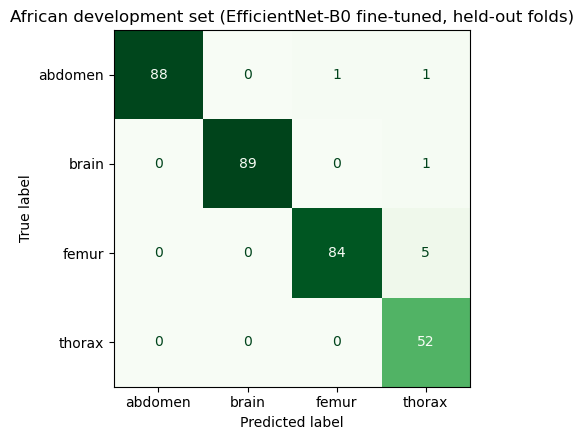

In [16]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(dev_labels, finetuned_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Greens", ax=ax, colorbar=False)
ax.set_title("African development set (EfficientNet-B0 fine-tuned, held-out folds)")
plt.tight_layout()
plt.savefig(FIGURES / "fig9_1_confusion_matrix_efficientnet_finetuned.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Final African model

One model is fine-tuned on all 321 development images with the same settings and saved for the later evaluations.

In [17]:
african_model, _ = new_african_model(dev_images, dev_labels, random_seed)
torch.save(african_model.state_dict(), MODELS / f"african_finetuned_{ARCH}.pt")
print("Saved:", MODELS / f"african_finetuned_{ARCH}.pt")

Saved: /Users/mac/Downloads/AISD/Project/fetal-ultrasound-plane-classification/models/african_finetuned_efficientnet_b0.pt


## 5. Summary

| | Accuracy (mean ± SD across folds) | Macro-F1 (mean ± SD across folds) | Correct images |
|---|---|---|---|
| EfficientNet-B0, Spanish model, no African training | 0.941 ± 0.019 | 0.934 ± 0.025 | 302 of 321 |
| EfficientNet-B0, fine-tuned on African images | 0.975 ± 0.009 | 0.971 ± 0.010 | 313 of 321 |
| ResNet18, fine-tuned (model training notebook, section 9) | 0.971 ± 0.014 | 0.967 ± 0.017 | 312 of 321 |

**Overall.** Fine-tuning raised EfficientNet-B0 from 94.1% to 97.5% accuracy and from 0.934 to 0.971 macro-F1, and every fold improved. The largest gain was in fold 5 (90.9% to 98.5%).

**The gain is clearer than for ResNet18.** Fine-tuning fixed 14 images and broke 3. If fine-tuning made no real difference, a split at least this uneven would occur about one time in eighty (sign test, p = 0.013). For ResNet18 the split was 11 and 5 (p = 0.21). EfficientNet-B0 started lower than ResNet18 and so had more to gain.

**Comparison with ResNet18.** After fine-tuning, the two networks are almost level: 313 against 312 correct images, with the same folds and settings. EfficientNet-B0 reaches this with about a third of the parameters.

**By plane and country.**

- **Thorax** reached 100% (52 of 52), up from 92.3%. Thorax was the weakest plane for the ResNet18 model (92.3% after fine-tuning).
- **Ghana**, the weakest country for the Spanish EfficientNet-B0 (78.9%), rose to 91.2%, but remains the weakest country (5 of 57 images wrong). Egypt rose from 92.2% to 98.7%, and Algeria and Uganda reached 100%.
- **Malawi** fell from 100% to 97.0% (two images), and abdomen did not change (97.8%).

**Remaining errors.** Of the 8 remaining errors, 5 are femur images, 2 abdomen and 1 brain. Unlike ResNet18, whose remaining errors were mostly abdomen and thorax confused with each other, EfficientNet-B0's weakness after fine-tuning is the femur plane.

**Next steps.** The final model, fine-tuned on all 321 development images, is saved in `models/african_finetuned_efficientnet_b0.pt`. The leave-one-site-out evaluation, the confidence threshold and the test set evaluation follow.


## 6. Leave-one-site-out evaluation

As for ResNet18 (model training notebook, section 10), one country at a time is held out: the Spanish EfficientNet-B0 is fine-tuned on the development images of the other four countries and scored on the held-out country. This shows how the model performs at a site it has never seen. The settings are the same as in section 3, and Ghana and Uganda have no thorax images, so their results cover three planes.

| Condition | African training images | Seen this country? |
|---|---|---|
| Spanish model (section 1) | None | No |
| Leave-one-site-out (this section) | The other four countries | No |
| Fine-tuned, patient-grouped folds (section 3) | All five countries | Yes, other patients |

### 6.1 Fine-tuning without each country

In [18]:
countries = development["Center"].to_numpy()
site_pred = np.zeros(len(development), dtype=int)
site_prob = np.zeros((len(development), len(PLANES)))

for country in sorted(development["Center"].unique()):
    train_rows = countries != country
    held_out = countries == country

    site_model, _ = new_african_model(dev_images[train_rows], dev_labels[train_rows], random_seed)
    _, pred, prob = predict(site_model, make_loader(dev_images[held_out], dev_labels[held_out]), device)
    site_pred[held_out] = pred
    site_prob[held_out] = prob
    print(f"{country}: trained on {train_rows.sum()} images | accuracy on {held_out.sum()} held-out images "
          f"{(pred == dev_labels[held_out]).mean():.3f}")

Algeria: trained on 261 images | accuracy on 60 held-out images 0.967
Egypt: trained on 244 images | accuracy on 77 held-out images 0.896
Ghana: trained on 264 images | accuracy on 57 held-out images 0.684
Malawi: trained on 254 images | accuracy on 67 held-out images 0.940
Uganda: trained on 261 images | accuracy on 60 held-out images 0.983


### 6.2 Results by country

Macro-F1 is calculated over the planes each country actually has.

In [19]:
def site_scores(pred):
    rows = {}
    for country in sorted(development["Center"].unique()):
        held_out = countries == country
        true = dev_labels[held_out]
        rows[country] = {"accuracy": (pred[held_out] == true).mean(),
                         "macro-F1": f1_score(true, pred[held_out], average="macro", labels=np.unique(true))}
    rows["All countries"] = {"accuracy": (pred == dev_labels).mean(),
                             "macro-F1": f1_score(dev_labels, pred, average="macro")}
    return pd.DataFrame(rows).T


site_results = pd.concat({
    "Spanish model": site_scores(pred_af),
    "Leave-one-site-out": site_scores(site_pred),
    "Fine-tuned (all countries)": site_scores(finetuned_pred),
}, axis=1)
site_results.round(3)

Spanish model          Leave-one-site-out           \
                   accuracy macro-F1           accuracy macro-F1   
Algeria               0.983    0.983              0.967    0.966   
Egypt                 0.922    0.925              0.896    0.897   
Ghana                 0.789    0.861              0.684    0.804   
Malawi                1.000    1.000              0.940    0.940   
Uganda                1.000    1.000              0.983    0.983   
All countries         0.941    0.934              0.897    0.888   

              Fine-tuned (all countries)           
                                accuracy macro-F1  
Algeria                            1.000    1.000  
Egypt                              0.987    0.987  
Ghana                              0.912    0.945  
Malawi                             0.970    0.970  
Uganda                             1.000    1.000  
All countries                      0.975    0.971

### 6.3 Errors on unseen sites

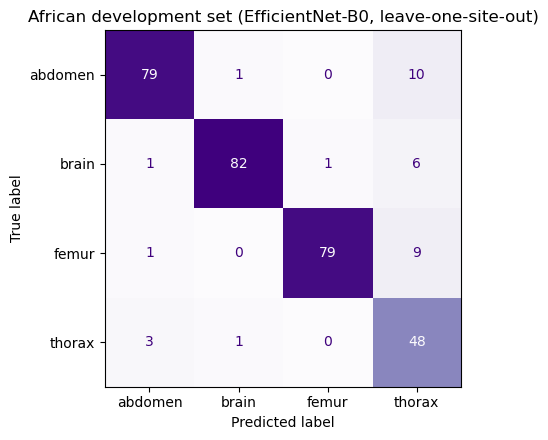

In [20]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(dev_labels, site_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Purples", ax=ax, colorbar=False)
ax.set_title("African development set (EfficientNet-B0, leave-one-site-out)")
plt.tight_layout()
plt.savefig(FIGURES / "fig9_2_confusion_matrix_efficientnet_leave_one_site_out.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
wrong = site_pred != dev_labels
errors = pd.DataFrame({"country": countries[wrong],
                       "predicted as": [SHORT_NAMES[i] for i in site_pred[wrong]]})
print("Misclassified images:", wrong.sum(),
      "| of these, correct for the Spanish model:", (pred_af[wrong] == dev_labels[wrong]).sum())
pd.crosstab(errors["country"], errors["predicted as"], margins=True)

Misclassified images: 33 | of these, correct for the Spanish model: 17


predicted as,abdomen,brain,femur,thorax,All
country,,,,,
Algeria,1,1,0,0,2
Egypt,4,0,0,4,8
Ghana,0,0,1,17,18
Malawi,0,0,0,4,4
Uganda,0,1,0,0,1
All,5,2,1,25,33


## 7. Leave-one-site-out summary

| Training condition | Seen this country? | EfficientNet-B0 accuracy | EfficientNet-B0 macro-F1 | ResNet18 accuracy (model training notebook) |
|---|---|---|---|---|
| Spanish model, no African training | No | 0.941 | 0.934 | 0.953 |
| Fine-tuned on the other four countries (leave-one-site-out) | No | 0.897 | 0.888 | 0.947 |
| Fine-tuned on all five countries (section 3) | Yes, other patients | 0.975 | 0.971 | 0.972 |

**Overall.** When a country was left out of training, fine-tuning on the other four countries made EfficientNet-B0 worse, not better: accuracy fell from 94.1% (Spanish model) to 89.7%, and every country dropped. Of the 33 misclassified images, 17 had been classified correctly by the Spanish model. As with ResNet18, the gains in section 3 come from having seen images from the same country, not from African data in general.

**Compared with ResNet18.** The drop is much larger than for ResNet18, which stayed close to its Spanish model (95.3% to 94.7%). At a site neither model had seen, EfficientNet-B0 was 5 percentage points behind ResNet18, although the two were level when every country had been seen (section 5).

**By country.** Ghana fell the most, from 78.9% to 68.4% (18 of 57 images wrong, against 11 for ResNet18). Egypt fell from 92.2% to 89.6%, Malawi from 100% to 94.0%, and Algeria and Uganda by one image each.

**Errors on unseen sites.** 25 of the 33 errors were predictions of thorax, including 17 of the 18 Ghana errors, a plane that Ghana did not collect. This is the same failure seen with ResNet18, but stronger: on an unfamiliar site, the fine-tuned model falls back on thorax.

**What this means for the model choice.** The selection rule compared the networks before any African training, where EfficientNet-B0 and ResNet18 were not significantly different. After fine-tuning on other African sites, EfficientNet-B0 generalised less well to a new site. The ranking before fine-tuning therefore did not predict the ranking at an unseen site.

**Caution.** Each network was trained once with one seed, and each country was held out once with 57 to 77 images, so one image changes a country's accuracy by about 1.5 percentage points. The ResNet18 predictions from its leave-one-site-out run were not saved, so the two networks are compared by their totals rather than image by image.


## 8. Test set evaluation

The final EfficientNet-B0 model (section 4) is scored **once** on the 75 African test images (23 patients), which have not been used for any training or decision. The Spanish EfficientNet-B0 and the final ResNet18 model (model training notebook, section 12) are scored on the same images for comparison.

The test patients come from the same five countries as the development patients, so this result corresponds to section 3 (sites the model has seen), not to section 6 (a new site). The 95% confidence intervals come from resampling the 23 test patients with replacement 1,000 times.

In [24]:
from sklearn.metrics import classification_report

test = african_clean[african_clean["partition"] == "test"]
test_images = african_images[test.index]
test_labels = test["label"].to_numpy()
test_loader = make_loader(test_images, test_labels)

final_model = load_model(MODELS / f"african_finetuned_{ARCH}.pt", device, arch=ARCH)
resnet_model = load_model(MODELS / "african_finetuned.pt", device, arch="resnet18")

_, test_pred, test_prob = predict(final_model, test_loader, device)
_, test_pred_spanish, _ = predict(spanish_model, test_loader, device)
_, test_pred_resnet, _ = predict(resnet_model, test_loader, device)
pd.crosstab(test["Center"], test["Plane"], margins=True)

Plane,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,All
Center,,,,,
Algeria,4,4,4,4,16
Egypt,3,4,4,3,14
Ghana,6,6,6,0,18
Malawi,3,4,3,2,12
Uganda,5,5,5,0,15
All,21,23,22,9,75


### 8.1 Overall scores with confidence intervals

In [25]:
def patient_bootstrap(true, pred, patients, n=1000):
    rng = np.random.default_rng(random_seed)
    ids = np.unique(patients)
    scores = []
    for _ in range(n):
        rows = np.concatenate([np.where(patients == p)[0] for p in rng.choice(ids, len(ids))])
        scores.append([(pred[rows] == true[rows]).mean(),
                       f1_score(true[rows], pred[rows], average="macro", labels=np.unique(true[rows]))])
    return np.percentile(scores, [2.5, 97.5], axis=0)


rows = {}
for name, pred in [("EfficientNet-B0, Spanish model", test_pred_spanish),
                   ("EfficientNet-B0, final African model", test_pred),
                   ("ResNet18, final African model", test_pred_resnet)]:
    low, high = patient_bootstrap(test_labels, pred, test["patient_id"].to_numpy())
    rows[name] = {
        "correct": f"{(pred == test_labels).sum()} of {len(test_labels)}",
        "accuracy": round((pred == test_labels).mean(), 3),
        "accuracy 95% CI": f"{low[0]:.3f} to {high[0]:.3f}",
        "macro-F1": round(f1_score(test_labels, pred, average="macro"), 3),
        "macro-F1 95% CI": f"{low[1]:.3f} to {high[1]:.3f}",
    }
pd.DataFrame(rows).T

,correct,accuracy,accuracy 95% CI,macro-F1,macro-F1 95% CI
"EfficientNet-B0, Spanish model",71 of 75,0.947,0.897 to 0.987,0.939,0.874 to 0.988
"EfficientNet-B0, final African model",71 of 75,0.947,0.897 to 0.987,0.939,0.877 to 0.988
"ResNet18, final African model",73 of 75,0.973,0.933 to 1.000,0.969,0.925 to 1.000


### 8.2 Results by plane and country

In [26]:
report = classification_report(test_labels, test_pred, target_names=SHORT_NAMES, output_dict=True)
pd.DataFrame(report).T.round(3)

,precision,recall,f1-score,support
abdomen,0.950,0.905,0.927,21.000
brain,1.000,1.000,1.000,23.000
femur,0.952,0.909,0.930,22.000
thorax,0.818,1.000,0.900,9.000
accuracy,0.947,0.947,0.947,0.947
macro avg,0.930,0.953,0.939,75.000
weighted avg,0.950,0.947,0.947,75.000


In [27]:
test_results = test.assign(spanish=(test_pred_spanish == test_labels), final=(test_pred == test_labels),
                           resnet=(test_pred_resnet == test_labels))
test_results.groupby("Center").agg(images=("final", "size"),
                                   **{"EfficientNet-B0, Spanish model": ("spanish", "mean"),
                                      "EfficientNet-B0, final": ("final", "mean"),
                                      "ResNet18, final": ("resnet", "mean")}).round(3)

,images,"EfficientNet-B0, Spanish model","EfficientNet-B0, final","ResNet18, final"
Center,,,,
Algeria,16,1.000,1.000,1.000
Egypt,14,0.929,0.929,0.929
Ghana,18,0.944,0.944,1.000
Malawi,12,1.000,1.000,1.000
Uganda,15,0.867,0.867,0.933


In [28]:
wrong = np.where(test_pred != test_labels)[0]
pd.DataFrame({"country": test["Center"].to_numpy()[wrong],
              "true plane": [SHORT_NAMES[i] for i in test_labels[wrong]],
              "predicted": [SHORT_NAMES[i] for i in test_pred[wrong]],
              "confidence": test_prob[wrong].max(axis=1).round(3)})

,country,true plane,predicted,confidence
0,Egypt,abdomen,thorax,0.646
1,Uganda,femur,thorax,0.757
2,Uganda,abdomen,femur,0.702
3,Ghana,femur,abdomen,0.466


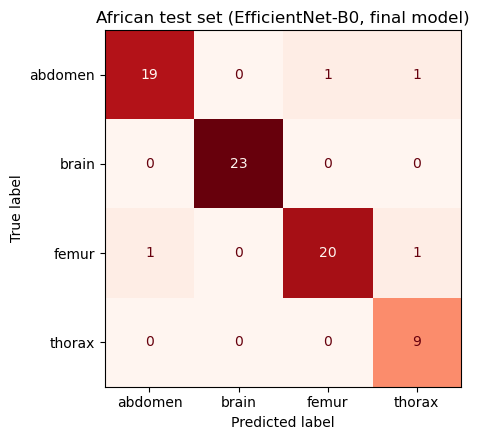

In [29]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(test_labels, test_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Reds", ax=ax, colorbar=False)
ax.set_title("African test set (EfficientNet-B0, final model)")
plt.tight_layout()
plt.savefig(FIGURES / "fig9_3_confusion_matrix_efficientnet_test.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Test set summary

| | Correct | Accuracy (95% CI) | Macro-F1 (95% CI) |
|---|---|---|---|
| EfficientNet-B0, Spanish model, no African training | 71 of 75 | 0.947 (0.897 to 0.987) | 0.939 (0.874 to 0.988) |
| **EfficientNet-B0, final African model** | **71 of 75** | **0.947 (0.897 to 0.987)** | **0.939 (0.877 to 0.988)** |
| ResNet18, final African model | 73 of 75 | 0.973 (0.933 to 1.000) | 0.969 (0.925 to 1.000) |

**Overall.** The final EfficientNet-B0 classified 71 of the 75 test images correctly (94.7%, macro-F1 0.939). This is lower than its cross-validation estimate (97.5%, section 3), and fine-tuning on the African development images brought no gain on the test set: the Spanish EfficientNet-B0 also got 71 correct, with the same accuracy in every country.

**Compared with ResNet18.** The final ResNet18 got 73 of 75 correct. The difference is two images and the confidence intervals overlap widely, so the test set cannot separate the two networks.

**By plane.** All 23 brain and all 9 thorax images were correct. The four errors were two abdomen images (one predicted as thorax, one as femur) and two femur images (one predicted as thorax, one as abdomen). Thorax precision was 0.818, because two other images were predicted as thorax.

**By country.** Algeria and Malawi were 100% correct. Uganda had two errors (86.7%), and Egypt and Ghana one each. Per-country scores are based on 12 to 18 images, so they are not compared further.

**Confidence.** All four errors had a highest predicted probability between 0.47 and 0.76. A confidence threshold for EfficientNet-B0 has not been chosen yet; it should be set on the development data, as for ResNet18, and not on these test results.

**What this means for the model choice.** Across the three evaluations after African training, EfficientNet-B0 was level with ResNet18 on the development folds (97.5% against 97.1%), behind on unseen sites (89.7% against 94.7%) and two images behind on the test set (94.7% against 97.3%). EfficientNet-B0 was chosen by the selection rule for being a third of the size with no significant loss before African training, but ResNet18 has been at least as accurate in every evaluation of the fine-tuned models and more robust at a new site. Each network was trained with one seed, and the test set is small.


## 10. Confidence threshold for human review

As for ResNet18 (model training notebook, section 14), images whose highest predicted probability is below a threshold are flagged for review by a sonographer or for reacquisition, and only the remaining images are labelled automatically.

The threshold is chosen on the development data only, from the out-of-fold probabilities in section 3, with the same rule as for ResNet18: **use the highest threshold that flags no more than 10% of development images**. It is then applied unchanged to the leave-one-site-out predictions (section 6) and to the test set (section 8). The test results in section 9 are not used to choose it.

### 10.1 Confidence of correct and incorrect predictions

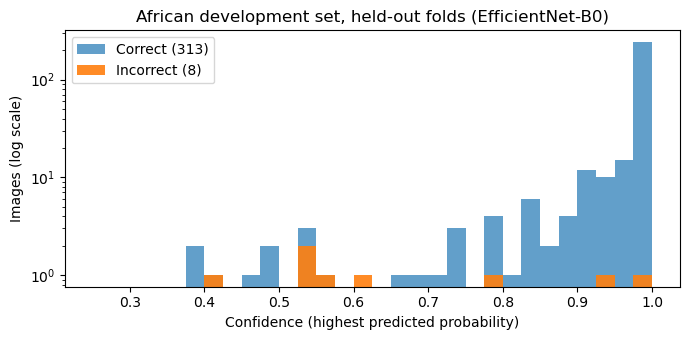

In [30]:
dev_confidence = finetuned_prob.max(axis=1)
dev_wrong = finetuned_pred != dev_labels

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0.25, 1.0, 31)
ax.hist(dev_confidence[~dev_wrong], bins=bins, alpha=0.7, label=f"Correct ({(~dev_wrong).sum()})")
ax.hist(dev_confidence[dev_wrong], bins=bins, alpha=0.9, label=f"Incorrect ({dev_wrong.sum()})")
ax.set_yscale("log")
ax.set_xlabel("Confidence (highest predicted probability)")
ax.set_ylabel("Images (log scale)")
ax.set_title("African development set, held-out folds (EfficientNet-B0)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig9_4_confidence_distribution_efficientnet.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.2 Effect of different thresholds on the development set

For each threshold: how many images would be flagged, how many of the errors would be among them, and the accuracy on the images that are labelled automatically.

In [31]:
def flagging_table(prob, true, thresholds):
    confidence = prob.max(axis=1)
    pred = prob.argmax(axis=1)
    wrong = pred != true
    rows = {}
    for threshold in thresholds:
        flagged = confidence < threshold
        rows[threshold] = {
            "flagged": f"{flagged.sum()} of {len(true)} ({flagged.mean():.1%})",
            "errors flagged": f"{(flagged & wrong).sum()} of {wrong.sum()}",
            "accuracy on accepted images": round((pred[~flagged] == true[~flagged]).mean(), 3),
        }
    return pd.DataFrame(rows).T.rename_axis("threshold")


flagging_table(finetuned_prob, dev_labels, [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99])

,flagged,errors flagged,accuracy on accepted images
threshold,,,
0.50,7 of 321 (2.2%),1 of 8,0.978
0.60,14 of 321 (4.4%),4 of 8,0.987
0.70,17 of 321 (5.3%),5 of 8,0.99
0.80,26 of 321 (8.1%),6 of 8,0.993
0.90,39 of 321 (12.1%),6 of 8,0.993
0.95,62 of 321 (19.3%),7 of 8,0.996
0.99,118 of 321 (36.8%),8 of 8,1.0


### 10.3 Choosing the threshold

In [32]:
max_flagged = 0.10
candidates = np.round(np.arange(0.50, 1.00, 0.01), 2)
threshold = max(t for t in candidates if (dev_confidence < t).mean() <= max_flagged)
print(f"Chosen threshold: {threshold:.2f}")

Chosen threshold: 0.84


### 10.4 The threshold on development, unseen sites and the test set

In [33]:
evaluations = {
    "Development, patient-grouped folds (section 3)": (finetuned_prob, dev_labels),
    "Development, leave-one-site-out (section 6)": (site_prob, dev_labels),
    "Test set (section 8)": (test_prob, test_labels),
}
pd.concat({name: flagging_table(prob, true, [threshold]) for name, (prob, true) in evaluations.items()}).droplevel(1)

,flagged,errors flagged,accuracy on accepted images
"Development, patient-grouped folds (section 3)",31 of 321 (9.7%),6 of 8,0.993
"Development, leave-one-site-out (section 6)",46 of 321 (14.3%),24 of 33,0.967
Test set (section 8),8 of 75 (10.7%),4 of 4,1.0


In [34]:
site_flagged = site_prob.max(axis=1) < threshold
site_wrong = site_pred != dev_labels
development.assign(flagged=site_flagged, wrong=site_wrong, flagged_and_wrong=site_flagged & site_wrong) \
    .groupby("Center")[["flagged", "wrong", "flagged_and_wrong"]].sum() \
    .rename(columns={"flagged": "images flagged", "wrong": "errors", "flagged_and_wrong": "errors flagged"})

,images flagged,errors,errors flagged
Center,,,
Algeria,3,2,2
Egypt,15,8,6
Ghana,18,18,11
Malawi,7,4,4
Uganda,3,1,1


## 11. Confidence threshold summary

The chosen threshold is **0.84**, the same value as for ResNet18: predictions with a highest probability below 0.84 are flagged for review.

| Evaluation | EfficientNet-B0: images flagged | Errors flagged | Accuracy on accepted images | ResNet18: errors flagged | ResNet18: accuracy on accepted images |
|---|---|---|---|---|---|
| Development, patient-grouped folds | 31 of 321 (9.7%) | 6 of 8 | 0.993 | 9 of 9 | 1.000 |
| Development, leave-one-site-out | 46 of 321 (14.3%) | 24 of 33 | 0.967 | 12 of 17 | 0.983 |
| Test set | 8 of 75 (10.7%) | 4 of 4 | 1.000 | 2 of 2 | 1.000 |

**Test set.** With the threshold fixed in advance, 8 of the 75 test images were flagged, including all 4 errors, and all 67 accepted images were correct. This is the same outcome as for ResNet18: after flagging, both models labelled the same number of test images automatically without error. With only 4 test errors, this is encouraging but not strong evidence on its own.

**Development folds.** The threshold caught 6 of the 8 errors. Unlike ResNet18, whose errors all had low confidence, EfficientNet-B0 made 2 errors with high confidence (one of them above 0.95), so accuracy on the accepted images was 99.3% rather than 100%.

**Unseen sites.** The threshold flagged more images than on the development folds (14.3%), which is expected on unfamiliar images, and caught 24 of the 33 errors, raising accuracy on the accepted images from 89.7% to 96.7%. However, 9 errors were made with high confidence and would not be flagged, against 5 for ResNet18. Seven of these were in Ghana, where 11 of the 18 errors were flagged; since 17 of Ghana's 18 errors were predictions of thorax (section 6.3), the confident errors are almost all thorax predictions. A model can be confidently wrong on images that look unlike anything it was trained on, so the confidence check does not replace a site-specific check before deployment.

**Note on the development result.** The threshold was chosen on the same development predictions it is evaluated on in the first row, although the rule only fixed the share of images flagged, not the number of errors caught. The test set and leave-one-site-out rows are the fairer measures.

**What this means for use.** With a threshold of 0.84, about one image in ten would be sent for review or reacquisition at known sites, and about one in seven at a new site. EfficientNet-B0 matches ResNet18 on the test set after flagging, but at a new site it leaves more confident errors (9 against 5) and a lower accuracy on the accepted images (96.7% against 98.3%).
